# 02 · Mudança conjunta de perfis observados

> Modelo reconstruído com `scale_pos_weight=13.882494684620836`; corte 0,50 somente para recall e precisão referenciais. A versão anterior permanece preservada.

**Pergunta.** Como Brier, AUC ROC, PR-AUC trapezoidal e KS do modelo evoluem quando pares de condições se tornam mais frequentes? Executamos **toda a grade**, sem limiar automático de aceitação ou parada.

**Passo a passo transferível:** (1) recuperar holdout rotulado e Booster congelado; (2) escolher condições A e B antes de consultar Y; (3) conferir tamanho e taxa de evento do grupo A∩B; (4) atribuir peso λ ao grupo e 1 aos demais; (5) medir o PSI da tabela 2×2 e ESS; (6) calcular as quatro métricas e seus deltas contra o baseline; (7) visualizar trajetórias e incerteza. A linha inteira e seu Y permanecem intactos, hipótese de mudança de composição P(X) com P(Y|X) estável. Não é intervenção causal sobre dois atributos de um cliente.

`cs-test.csv` não tem Y: ali calculamos apenas diagnóstico de domínio e participação das quatro células, nunca desempenho de crédito.

In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, precision_recall_curve, roc_curve, auc as area_curva
from sklearn.ensemble import HistGradientBoostingClassifier
from IPython.display import display

SEED = 33
FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines', 'age',
    'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents'
]
# Ajuste DATA_DIR se os CSVs estiverem em outro local.
P = DATA_DIR_PROJECT
DATA_DIR = next((d for d in (P, P.parent) if (d / 'cs-training.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Coloque os CSVs em data/raw/ e execute a partir da raiz do projeto ou de notebooks/.')
OUTPUT_DIR = TABLES_DIR
MODEL_PATH = MODEL_DIR / 'model_class_retreinado.json'
RESULTS_PATH = OUTPUT_DIR / 'resultados_multivariado.csv'
if not MODEL_PATH.exists():
    raise FileNotFoundError(f'Modelo ausente: {MODEL_PATH}. Execute primeiro o notebook de reconstrução.')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Modelo:', MODEL_PATH)
print('Resultados:', RESULTS_PATH)

Modelo: .\models\model_class_retreinado.json
Resultados: .\results\tables\resultados_multivariado.csv


In [3]:
# Verifica que o modelo, o manifesto e a configuração deste estudo coincidem.
import hashlib as _hashlib
import json as _json
_manifesto_versao = _json.loads(
    (MODEL_DIR / "manifesto_modelo.json").read_text(encoding="utf-8")
)
assert abs(_manifesto_versao["params_fornecidos"]["scale_pos_weight"]
           - 13.882494684620836) < 1e-12
assert _manifesto_versao["cutoff"] == 0.5
assert _manifesto_versao["features"] == FEATURES
_arquivo_modelo_versao = MODEL_DIR / "model_class_retreinado.json"
assert _hashlib.sha256(_arquivo_modelo_versao.read_bytes()).hexdigest() == \
       _manifesto_versao["model_sha256"], "Booster e manifesto divergentes."
print("Modelo validado:", _manifesto_versao["variant"])


Modelo validado: metricas_brier_auc_prauc_ks_grade_5a50


## 1. Recuperar exatamente a divisão original

O notebook de origem separa primeiro 15% para teste (`random_state=33`), sem estratificação, e depois 17,65% dos 85% restantes para validação. Repetimos essas chamadas para evitar avaliar o modelo em linhas de treino. Nenhum peso ou condição usa o rótulo para escolher as linhas.

In [4]:
df = pd.read_csv(DATA_DIR / 'cs-training.csv').drop(columns='Unnamed: 0')
assert df['SeriousDlqin2yrs'].notna().all()
assert list(df.drop(columns='SeriousDlqin2yrs').columns) == FEATURES
X = df[FEATURES]
y = df['SeriousDlqin2yrs'].astype(int)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1765, random_state=SEED
)
print(f'Treino: {len(X_train):,}; validação: {len(X_val):,}; teste: {len(X_test):,}')
print(f'Prevalência de evento no teste: {y_test.mean():.3%}')
assert len(X_test) == 22500

Treino: 104,996; validação: 22,504; teste: 22,500

Prevalência de evento no teste: 6.667%


## 2. Escorar uma vez com todas as árvores

O modelo fica congelado. Usamos explicitamente todas as iterações da árvore para manter a avaliação coerente com `model_class.predict(dtest)` no notebook original. Reponderar linhas altera a população avaliada, não as previsões individuais.

In [5]:
model = xgb.Booster()
model.load_model(str(MODEL_PATH))
if model.feature_names is not None:
    assert model.feature_names == FEATURES, (model.feature_names, FEATURES)
dtest = xgb.DMatrix(X_test, feature_names=FEATURES, enable_categorical=True)
n_trees = model.num_boosted_rounds()
p_test = model.predict(dtest, iteration_range=(0, n_trees))
y_array = y_test.to_numpy(dtype=int)
assert len(p_test) == len(X_test) and np.isfinite(p_test).all()
print(f'Árvores usadas: {n_trees:,}; score mínimo/máximo: {p_test.min():.5f} / {p_test.max():.5f}')

Árvores usadas: 103; score mínimo/máximo: 0.03601 / 0.97662


## 3. Cenários conjuntos pré-definidos

Todos os limiares são fixos e interpretáveis. Os sete cenários incluem perfis de risco elevado, perfis de menor risco e qualidade de dados. A última situação testa **ausência de renda correlacionada com utilização alta**; não inventa valores de renda.

| Cenário | Condição A | Condição B |
|---|---|---|
| Utilização e dívida | utilização ≥ 0,75 | razão de dívida ≥ 0,5 |
| Jovem e atraso curto | idade < 40 | ao menos um atraso de 30 a 59 dias |
| Renda baixa e dívida | renda mensal ≤ 4.000 | razão de dívida ≥ 0,5 |
| Crédito e imóveis | ao menos 12 linhas abertas | ao menos 2 empréstimos imobiliários |
| Atrasos combinados | ao menos um atraso de 90 dias | ao menos um atraso de 60 a 89 dias |
| Renda ausente e utilização | renda mensal ausente | utilização ≥ 0,5 |
| Idoso e dependentes | idade ≥ 60 | ao menos 2 dependentes |

O grupo estressado é sempre **A ∩ B**. Para medir a mudança conjunta, dividimos a população nas quatro células (não A/não B, não A/B, A/não B, A/B) e calculamos o PSI entre as frequências antes e depois da reponderação. PSI é uma medida de distância, sem limite universal de aprovação.

In [6]:
def scenario_masks(frame):
    return {
        'Utilização e dívida': (
            frame['RevolvingUtilizationOfUnsecuredLines'].ge(0.75), frame['DebtRatio'].ge(0.5)
        ),
        'Jovem e atraso curto': (
            frame['age'].lt(40), frame['NumberOfTime30-59DaysPastDueNotWorse'].ge(1)
        ),
        'Renda baixa e dívida': (
            frame['MonthlyIncome'].le(4000), frame['DebtRatio'].ge(0.5)
        ),
        'Crédito e imóveis': (
            frame['NumberOfOpenCreditLinesAndLoans'].ge(12), frame['NumberRealEstateLoansOrLines'].ge(2)
        ),
        'Atrasos combinados': (
            frame['NumberOfTimes90DaysLate'].ge(1), frame['NumberOfTime60-89DaysPastDueNotWorse'].ge(1)
        ),
        'Renda ausente e utilização': (
            frame['MonthlyIncome'].isna(), frame['RevolvingUtilizationOfUnsecuredLines'].ge(0.5)
        ),
        'Idoso e dependentes': (
            frame['age'].ge(60), frame['NumberOfDependents'].ge(2)
        ),
    }

# Razão entre o peso de A ∩ B e o peso das demais linhas.
INTENSIDADES = np.array([1.0, 1.25, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0, 16.0])

In [7]:
base_sizes = []
for nome, (a, b) in scenario_masks(X_test).items():
    evento = np.asarray(a & b)
    base_sizes.append({
        'cenário': nome, 'n_A_inter_B': int(evento.sum()),
        'participação_basal': evento.mean(),
        'evento_no_grupo': y_array[evento].mean(),
    })
display(pd.DataFrame(base_sizes).style.format({
    'participação_basal': '{:.2%}', 'evento_no_grupo': '{:.2%}'
}))
assert all(row['n_A_inter_B'] >= 200 for row in base_sizes), 'Grupo muito pequeno para estes limiares.'

,cenário,n_A_inter_B,participação_basal,evento_no_grupo
0,Utilização e dívida,1545,6.87%,22.46%
1,Jovem e atraso curto,943,4.19%,27.68%
2,Renda baixa e dívida,2177,9.68%,8.68%
3,Crédito e imóveis,2531,11.25%,6.76%
4,Atrasos combinados,416,1.85%,57.69%
5,Renda ausente e utilização,981,4.36%,20.39%
6,Idoso e dependentes,372,1.65%,4.03%


## 4. Métricas e distância conjunta

Se A∩B representa um perfil de interesse, $w_i=\lambda$ nas linhas do perfil e $w_i=1$ nas demais. A normalização para média 1 não altera métricas ponderadas. $\lambda=1$ reproduz o holdout; valores maiores aumentam a participação do perfil. **λ é razão de pesos, não percentual de mudança em X.** O PSI conjunto mede o deslocamento nas quatro células 00, 01, 10 e 11, usando as proporções originais como referência.

As métricas centrais são Brier $\sum w_i(y_i-p_i)^2/\sum w_i$ (menor melhor), AUC ROC (área TPR×FPR), PR-AUC trapezoidal `auc(recall,precision)` e KS do modelo $\max_t[TPR(t)-FPR(t)]$ (as três últimas maiores melhor). $t$ percorre todos os scores distintos. AP é indicador adicional e difere da área trapezoidal. Recall e precisão em 0,50 são referenciais. ESS $(\sum w)^2/\sum w^2$ e número de eventos sustentam a leitura, sem invalidar automaticamente um ponto. Não confundimos KS do modelo com KS de drift das entradas.

In [8]:
def joint_cell(a, b):
    return (2 * np.asarray(a, dtype=int) + np.asarray(b, dtype=int)).astype(int)

def joint_psi(cell, weight):
    eps = 1e-12
    p = np.bincount(cell, minlength=4).astype(float)
    q = np.bincount(cell, weights=weight, minlength=4).astype(float)
    p = (p + eps) / (p.sum() + 4 * eps)
    q = (q + eps) / (q.sum() + 4 * eps)
    return float(np.sum((q - p) * np.log(q / p)))

def weighted_metrics(y_true, score, weight):
    weight = np.asarray(weight, dtype=float)
    pred = score >= 0.5
    tp = weight[(y_true == 1) & pred].sum()
    fp = weight[(y_true == 0) & pred].sum()
    tn = weight[(y_true == 0) & ~pred].sum()
    fn = weight[(y_true == 1) & ~pred].sum()
    prec_curve, rec_curve, _ = precision_recall_curve(y_true, score, sample_weight=weight)
    fpr_curve, tpr_curve, _ = roc_curve(y_true, score, sample_weight=weight)
    ap = average_precision_score(y_true, score, sample_weight=weight)
    prev = np.average(y_true, weights=weight)
    return {
        'auc': roc_auc_score(y_true, score, sample_weight=weight),
        'prauc_trap': area_curva(rec_curve, prec_curve),
        'ks_modelo': float(np.max(tpr_curve-fpr_curve)),
        'brier': brier_score_loss(y_true, score, sample_weight=weight),
        'ap': ap, 'ap_lift': ap/prev,
        'recall_05': tp / (tp + fn),
        'precision_05': tp / (tp + fp) if tp + fp else np.nan,
        'fpr_05': fp / (fp + tn),
        'prevalencia': prev,
        'ess': weight.sum() ** 2 / np.sum(weight ** 2),
    }

baseline = weighted_metrics(y_array, p_test, np.ones(len(y_array)))
rows = []
for nome, (a, b) in scenario_masks(X_test).items():
    cell = joint_cell(a, b)
    grupo = cell == 3
    for intensidade in INTENSIDADES:
        weight = np.where(grupo, intensidade, 1.0)
        weight = weight / weight.mean()
        row = {
            'cenario': nome, 'intensidade': intensidade,
            'participacao_grupo': np.average(grupo, weights=weight),
            'joint_psi': joint_psi(cell, weight),
            'n_grupo_original': int(grupo.sum()),
        }
        row.update(weighted_metrics(y_array, p_test, weight))
        row['ess_ratio'] = row['ess'] / len(y_array)
        rows.append(row)
resultados = pd.DataFrame(rows)
for campo in ['auc','prauc_trap','ks_modelo','brier','ap','recall_05','precision_05','fpr_05','prevalencia']:
    resultados[f'delta_{campo}'] = resultados[campo] - baseline[campo]
resultados['razao_brier'] = resultados['brier'] / baseline['brier']
resultados['ess_ratio'] = resultados['ess'] / len(y_array)
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)
resultados.to_csv(RESULTS_PATH, index=False, encoding='utf-8-sig')
print('Métricas basais (holdout rotulado):')
display(pd.DataFrame([baseline]).round(5))
print(f'{len(resultados)} avaliações salvas em {RESULTS_PATH}')

Métricas basais (holdout rotulado):


,auc,prauc_trap,ks_modelo,brier,ap,ap_lift,recall_05,precision_05,fpr_05,prevalencia,ess
0,0.86684,0.39599,0.58771,0.14404,0.39639,5.94578,0.794,0.21525,0.20676,0.06667,22500.0


70 avaliações salvas em .\results\tables\resultados_multivariado.csv


In [9]:
resumo = resultados.groupby('cenario', as_index=False).agg(
    n_cenarios=('intensidade','count'), psi_min=('joint_psi','min'), psi_max=('joint_psi','max'),
    ess_ratio_min=('ess_ratio','min'), auc_min=('auc','min'), auc_max=('auc','max'),
    prauc_trap_min=('prauc_trap','min'), prauc_trap_max=('prauc_trap','max'),
    ks_modelo_min=('ks_modelo','min'), ks_modelo_max=('ks_modelo','max'),
    brier_min=('brier','min'), brier_max=('brier','max'))
for campo in ['auc','prauc_trap','ks_modelo','brier']:
    extremos = resultados.groupby('cenario')[f'delta_{campo}'].agg(['min','max']).reset_index()
    resumo = resumo.merge(extremos.rename(columns={'min':f'delta_{campo}_min','max':f'delta_{campo}_max'}), on='cenario')
display(resumo.round(5))

,cenario,n_cenarios,psi_min,psi_max,ess_ratio_min,auc_min,auc_max,prauc_trap_min,prauc_trap_max,ks_modelo_min,...,brier_min,brier_max,delta_auc_min,delta_auc_max,delta_prauc_trap_min,delta_prauc_trap_max,delta_ks_modelo_min,delta_ks_modelo_max,delta_brier_min,delta_brier_max
0,Atrasos combinados,10,0.0,0.59085,0.28551,0.86684,0.90436,0.39599,0.62064,0.58771,...,0.14404,0.19363,0.00000,0.03752,0.00000,0.22465,0.00000,0.10863,0.00000,0.04959
1,Crédito e imóveis,10,0.0,1.54504,0.24328,0.82868,0.86684,0.35327,0.39599,0.52667,...,0.14404,0.16634,-0.03816,0.00000,-0.04272,0.00000,-0.06104,0.00000,0.00000,0.02230
2,Idoso e dependentes,10,0.0,0.54185,0.29860,0.86684,0.87896,0.39599,0.39733,0.58771,...,0.13203,0.14404,0.00000,0.01212,0.00000,0.00134,0.00000,0.03210,-0.01201,0.00000
3,Jovem e atraso curto,10,0.0,1.02537,0.22696,0.85740,0.87390,0.39599,0.51738,0.55071,...,0.14404,0.24079,-0.00944,0.00706,0.00000,0.12139,-0.03701,0.01296,0.00000,0.09675
4,Renda ausente e utilização,10,0.0,1.04850,0.22576,0.86684,0.87478,0.39599,0.49832,0.58771,...,0.14404,0.20230,0.00000,0.00794,0.00000,0.10233,0.00000,0.01133,0.00000,0.05826
5,Renda baixa e dívida,10,0.0,1.48271,0.23406,0.83474,0.86684,0.39306,0.39599,0.52315,...,0.14404,0.18004,-0.03210,0.00000,-0.00293,0.00000,-0.06456,0.00000,0.00000,0.03600
6,Utilização e dívida,10,0.0,1.31018,0.22263,0.85256,0.87143,0.39599,0.51997,0.55403,...,0.14404,0.25257,-0.01428,0.00459,0.00000,0.12398,-0.03368,0.00260,0.00000,0.10853


### Incerteza amostral de um nível pré-fixado

Escolhemos $\lambda=4$ para os sete pares **antes de consultar o desfecho do cenário**. Em 100 reamostragens pareadas do holdout, baseline e cenário recebem os mesmos índices. Mostramos o intervalo percentílico dos deltas nas quatro métricas. Isto cobre apenas variação amostral condicional ao modelo e ao mecanismo; não inclui incerteza do treinamento, seleção dos pares, mudança de conceito ou extrapolação além do suporte. O nível 4 é uma ilustração, não um limiar de parada.

In [10]:
rng = np.random.default_rng(SEED + 2026)
N_BOOT = 100
LAM_BOOT = 4.0
boot_rows = []
lookup = scenario_masks(X_test)
for nome, (a,b) in lookup.items():
    weight = np.where(np.asarray(a & b), LAM_BOOT, 1.0)
    boot = {campo: [] for campo in ['auc','prauc_trap','ks_modelo','brier']}
    for _ in range(N_BOOT):
        idx = rng.integers(0, len(y_array), len(y_array))
        yy, pp, ww = y_array[idx], p_test[idx], weight[idx]
        basal_b = weighted_metrics(yy, pp, np.ones(len(idx)))
        stress_b = weighted_metrics(yy, pp, ww)
        for campo in boot:
            boot[campo].append(stress_b[campo]-basal_b[campo])
    row = {'cenario':nome,'intensidade_avaliada':LAM_BOOT}
    for campo, amostras in boot.items():
        row[f'delta_{campo}_ic95_inf'],row[f'delta_{campo}_ic95_sup'] = np.quantile(amostras,[.025,.975])
    boot_rows.append(row)
incerteza = pd.DataFrame(boot_rows)
display(incerteza.round(5))

,cenario,intensidade_avaliada,delta_auc_ic95_inf,delta_auc_ic95_sup,delta_prauc_trap_ic95_inf,delta_prauc_trap_ic95_sup,delta_ks_modelo_ic95_inf,delta_ks_modelo_ic95_sup,delta_brier_ic95_inf,delta_brier_ic95_sup
0,Utilização e dívida,4.0,0.00003,0.01025,0.05089,0.08754,-0.01794,0.01760,0.03387,0.03921
1,Jovem e atraso curto,4.0,0.00320,0.01187,0.04394,0.07912,0.00123,0.02419,0.02487,0.03055
2,Renda baixa e dívida,4.0,-0.01696,-0.00577,-0.01310,0.01820,-0.03808,-0.01227,0.01173,0.01547
3,Crédito e imóveis,4.0,-0.02340,-0.00764,-0.03023,0.00314,-0.04546,-0.00724,0.00746,0.01052
4,Atrasos combinados,4.0,0.02135,0.03054,0.09400,0.14229,0.04053,0.06150,0.00911,0.01462
5,Renda ausente e utilização,4.0,0.00200,0.01081,0.02352,0.06322,-0.00103,0.02279,0.01528,0.01863
6,Idoso e dependentes,4.0,0.00092,0.00433,-0.00406,0.00436,0.00121,0.01143,-0.00338,-0.00226


## 5. Evolução das quatro métricas

Cada ponto representa uma razão de pesos λ executada. A linha pontilhada é o baseline do holdout, não uma meta. O segundo mapa mostra diferenças na maior intensidade testada para comparar os perfis sob **mesma regra de ponderação**; o PSI alcançado pode diferir por tamanho do grupo. AP, prevalência, ESS, recall e precisão a 0,50 ficam disponíveis no CSV.

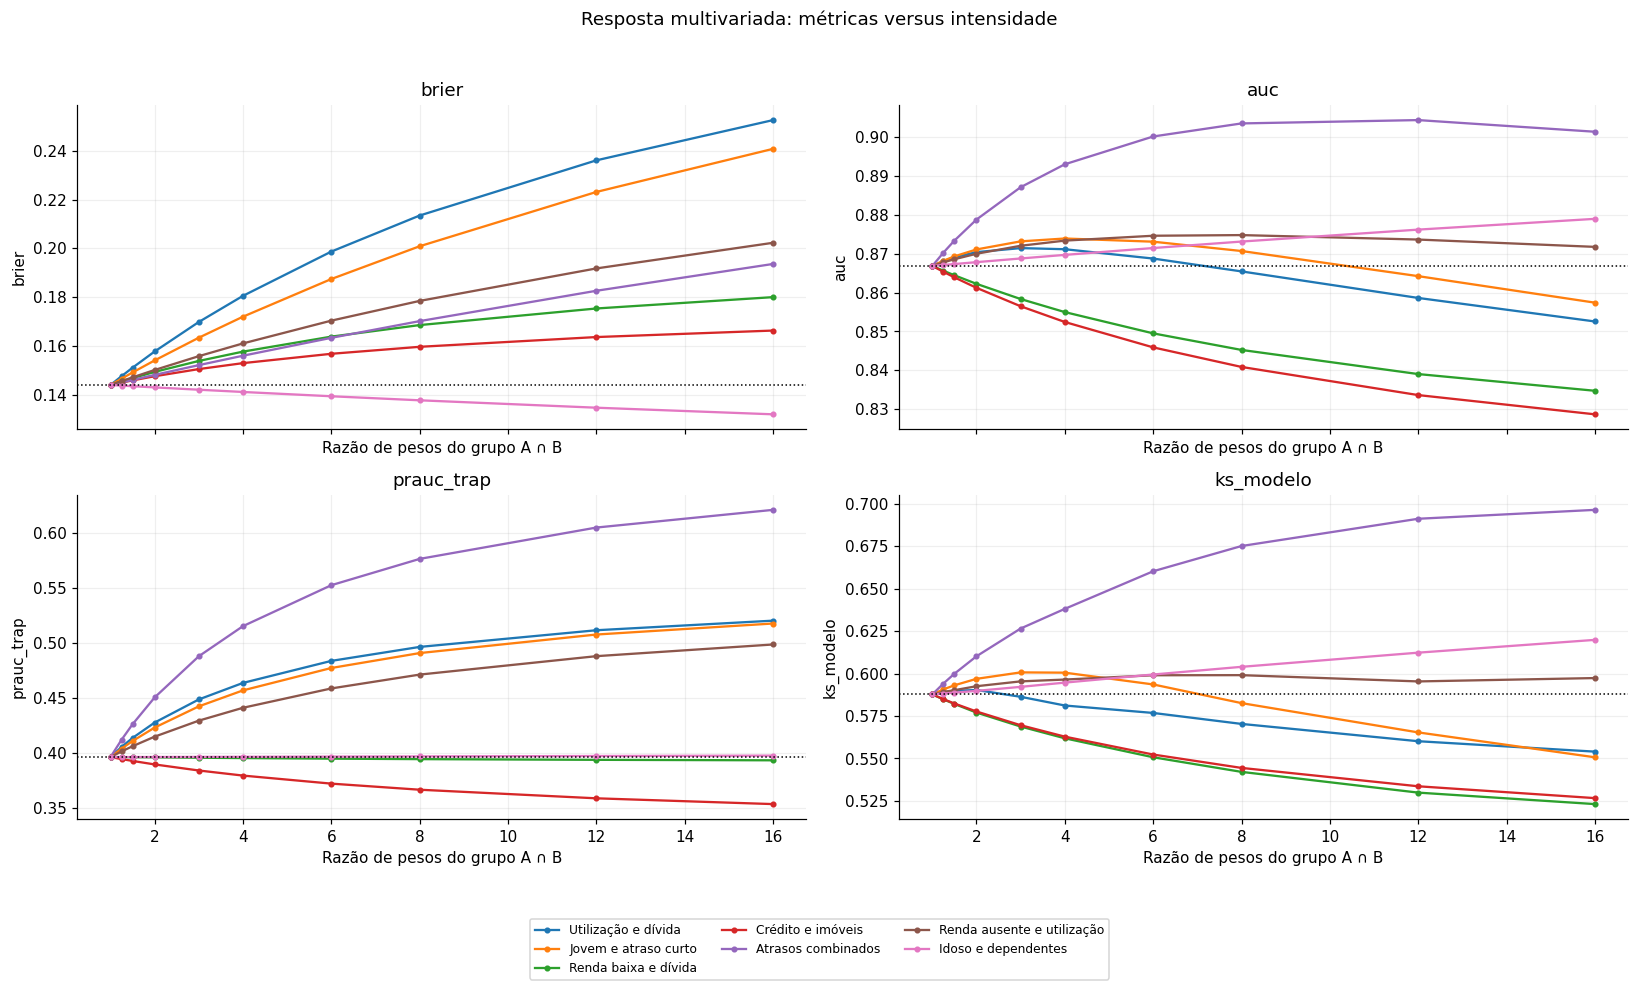

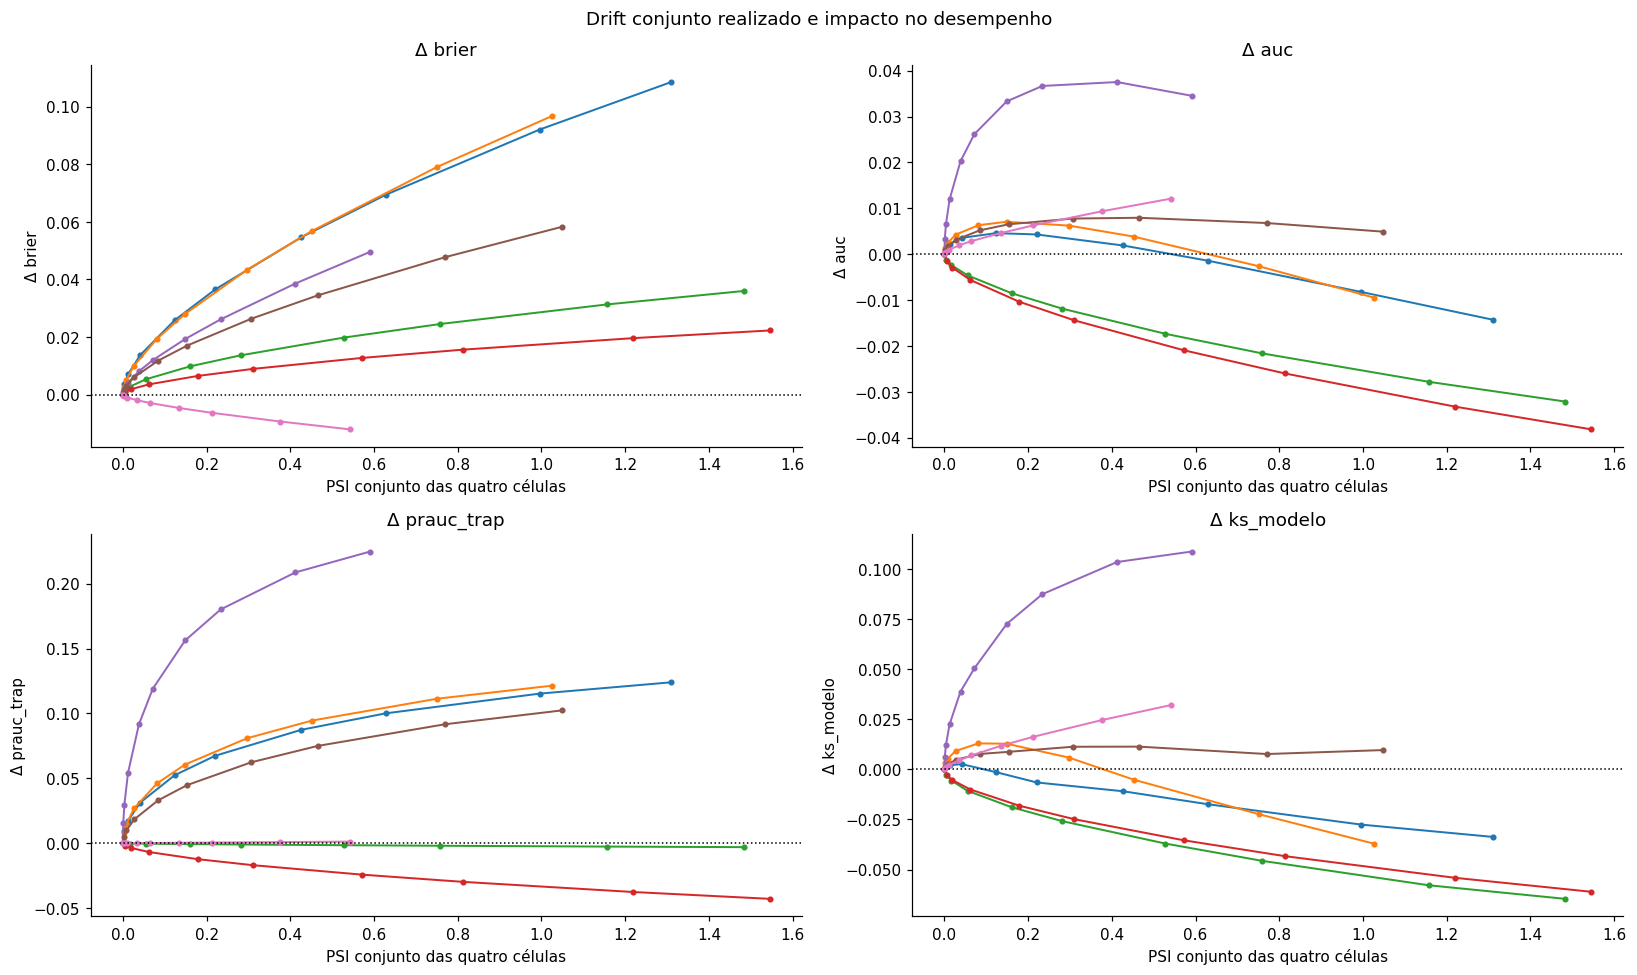

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
for ax, campo in zip(axes.flat, ['brier','auc','prauc_trap','ks_modelo']):
    for nome, sub in resultados.groupby('cenario', sort=False):
        ax.plot(sub['intensidade'], sub[campo], marker='o', markersize=3, lw=1.5, label=nome)
    ax.axhline(baseline[campo], color='black', ls=':', lw=1)
    ax.set(title=campo, xlabel='Razão de pesos do grupo A ∩ B', ylabel=campo)
    ax.grid(alpha=.2)
handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=8)
fig.suptitle('Resposta multivariada: métricas versus intensidade')
fig.tight_layout(rect=(0,.10,1,.96)); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, campo in zip(axes.flat, ['brier','auc','prauc_trap','ks_modelo']):
    for nome, sub in resultados.groupby('cenario', sort=False):
        ax.plot(sub['joint_psi'], sub[f'delta_{campo}'], marker='o', markersize=3, lw=1.3, label=nome)
    ax.axhline(0, color='black', ls=':', lw=1)
    ax.set(title=f'Δ {campo}', xlabel='PSI conjunto das quatro células', ylabel=f'Δ {campo}')
fig.suptitle('Drift conjunto realizado e impacto no desempenho')
fig.tight_layout(); plt.show()

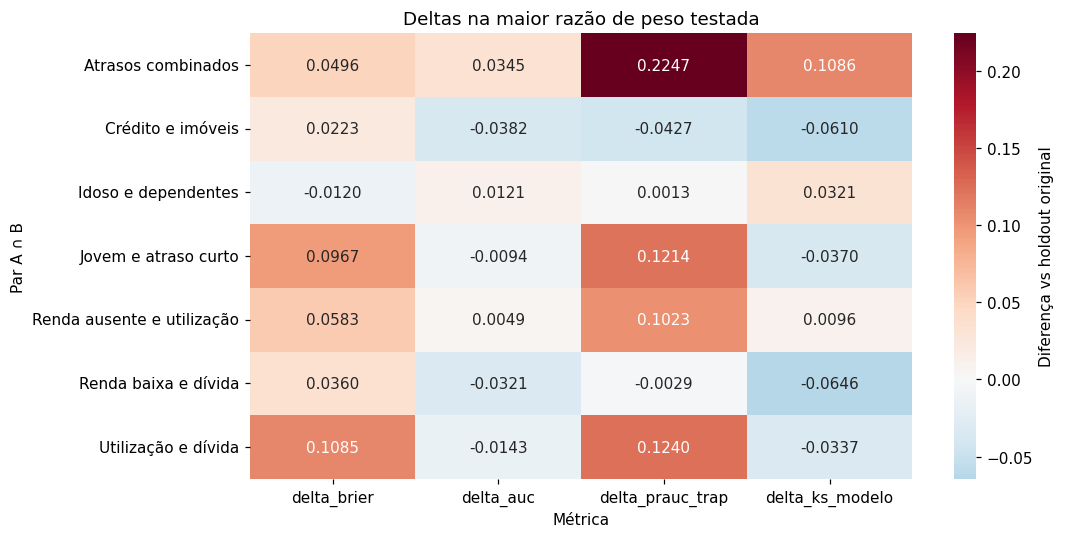

In [12]:
mais_forte = resultados.loc[resultados.groupby('cenario')['intensidade'].idxmax()]
tabela_delta = mais_forte.set_index('cenario')[[f'delta_{c}' for c in ['brier','auc','prauc_trap','ks_modelo']]]
fig, ax = plt.subplots(figsize=(10,5))
sns.heatmap(tabela_delta, annot=True, fmt='.4f', center=0, cmap='RdBu_r', ax=ax,
            cbar_kws={'label':'Diferença vs holdout original'})
ax.set(title='Deltas na maior razão de peso testada', xlabel='Métrica', ylabel='Par A ∩ B')
plt.tight_layout(); plt.show()

## 6. Diagnóstico do `cs-test.csv` sem rótulo

O teste de domínio treina um classificador para distinguir linhas do treinamento e linhas de `cs-test.csv`. AUC perto de 0,5 significa que ele não encontrou separação útil nesta amostra; valores maiores indicam diferenças conjuntas detectáveis. Treino e avaliação do classificador de domínio são separados. Isto **não** é a AUC de crédito do `model_class` em `cs-test.csv`. A heatmap abaixo mede, em pontos percentuais, a mudança das quatro células de cada par entre os arquivos originais.

In [13]:
df_unlabeled = pd.read_csv(DATA_DIR / 'cs-test.csv')
assert df_unlabeled['SeriousDlqin2yrs'].isna().all(), 'O arquivo foi alterado e agora tem rótulos; rever o desenho.'
assert list(df_unlabeled.drop(columns=['Unnamed: 0', 'SeriousDlqin2yrs']).columns) == FEATURES
X_unlabeled = df_unlabeled[FEATURES]

# Amostras balanceadas para que a AUC de domínio não dependa do tamanho dos arquivos.
n_domain = min(30000, len(X), len(X_unlabeled))
ref_sample = X.sample(n_domain, random_state=SEED)
new_sample = X_unlabeled.sample(n_domain, random_state=SEED)
domain_X = pd.concat([ref_sample, new_sample], ignore_index=True)
domain_y = np.r_[np.zeros(n_domain, dtype=int), np.ones(n_domain, dtype=int)]
Xd_train, Xd_hold, yd_train, yd_hold = train_test_split(
    domain_X, domain_y, test_size=0.30, random_state=SEED, stratify=domain_y
)
domain_clf = HistGradientBoostingClassifier(
    max_iter=75, max_leaf_nodes=15, learning_rate=0.07, random_state=SEED
)
domain_clf.fit(Xd_train, yd_train)
domain_score = domain_clf.predict_proba(Xd_hold)[:, 1]
domain_auc = roc_auc_score(yd_hold, domain_score)
domain_rng = np.random.default_rng(SEED + 17)
domain_boot = []
yd_hold_np = np.asarray(yd_hold)
for _ in range(200):
    ii = domain_rng.integers(0, len(yd_hold_np), len(yd_hold_np))
    domain_boot.append(roc_auc_score(yd_hold_np[ii], domain_score[ii]))
domain_ci = np.quantile(domain_boot, [.025, .975])
print(f'AUC de domínio em holdout (training vs cs-test): {domain_auc:.4f} '
      f'(IC 95% bootstrap {domain_ci[0]:.4f}–{domain_ci[1]:.4f})')
print(f'cs-test: {len(X_unlabeled):,} linhas e nenhum rótulo de crédito; não é possível calcular desempenho ali.')

AUC de domínio em holdout (training vs cs-test): 0.5021 (IC 95% bootstrap 0.4940–0.5103)
cs-test: 101,503 linhas e nenhum rótulo de crédito; não é possível calcular desempenho ali.


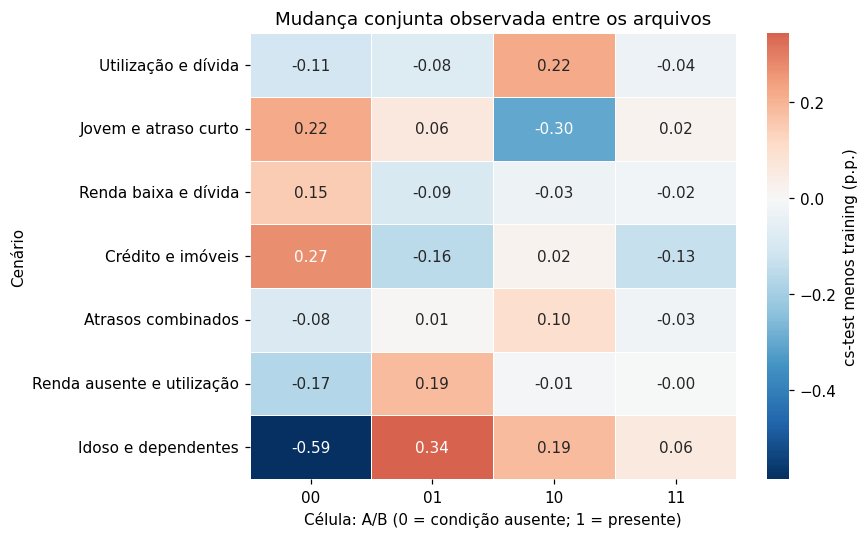

,00,01,10,11
cenário,,,,
Utilização e dívida,-0.107,-0.081,0.224,-0.036
Jovem e atraso curto,0.221,0.064,-0.304,0.020
Renda baixa e dívida,0.148,-0.094,-0.032,-0.022
Crédito e imóveis,0.274,-0.159,0.019,-0.135
Atrasos combinados,-0.083,0.008,0.100,-0.026
Renda ausente e utilização,-0.170,0.186,-0.013,-0.003
Idoso e dependentes,-0.586,0.344,0.186,0.057


In [14]:
def cell_shares(frame, a, b):
    return np.bincount(joint_cell(a, b), minlength=4) / len(frame)

shift_rows = []
for nome in scenario_masks(X).keys():
    a_ref, b_ref = scenario_masks(X)[nome]
    a_new, b_new = scenario_masks(X_unlabeled)[nome]
    delta_pp = 100 * (
        cell_shares(X_unlabeled, a_new, b_new) - cell_shares(X, a_ref, b_ref)
    )
    shift_rows.append([nome, *delta_pp])
joint_shift = pd.DataFrame(shift_rows, columns=['cenário', '00', '01', '10', '11']).set_index('cenário')
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(joint_shift, annot=True, fmt='.2f', center=0, cmap='RdBu_r',
            cbar_kws={'label': 'cs-test menos training (p.p.)'}, linewidths=.5, ax=ax)
ax.set_title('Mudança conjunta observada entre os arquivos')
ax.set_xlabel('Célula: A/B (0 = condição ausente; 1 = presente)')
ax.set_ylabel('Cenário')
plt.tight_layout()
plt.show()
display(joint_shift.round(3))

## 7. Reutilização e limites

1. Defina pares por relevância operacional antes de examinar Y; documente suas prevalências e contagens.
2. Use a mesma linha inteira ao reponderar. Isso preserva combinações observadas; a correlação agregada pode mudar.
3. Informe **intensidade aplicada e drift realizado**. λ, PSI e pontos percentuais do grupo são escalas distintas.
4. Compare as quatro métricas com o baseline próprio e veja a trajetória inteira. Recall e precisão a 0,50 são descritivos.
5. Trate ESS baixo e grupos pequenos como limitações de precisão, sem transformar um número arbitrário em reprovação.
6. Em produção, reproduza bins e perfis em janelas temporais e obtenha Y observado após maturação. `cs-test.csv` só permite observação de X.

A AUC do classificador de domínio é uma métrica de **distinção entre datasets**, não a AUC de crédito do modelo congelado. O PSI das quatro células depende das definições de A e B.

In [15]:
print('Amplitude de impacto para os sete pares na grade completa:')
display(resumo[['cenario','psi_max','ess_ratio_min',
 'delta_auc_min','delta_auc_max','delta_prauc_trap_min','delta_prauc_trap_max',
 'delta_ks_modelo_min','delta_ks_modelo_max','delta_brier_min','delta_brier_max']].round(5))
print('CSV detalhado:', RESULTS_PATH)

Amplitude de impacto para os sete pares na grade completa:


,cenario,psi_max,ess_ratio_min,delta_auc_min,delta_auc_max,delta_prauc_trap_min,delta_prauc_trap_max,delta_ks_modelo_min,delta_ks_modelo_max,delta_brier_min,delta_brier_max
0,Atrasos combinados,0.59085,0.28551,0.00000,0.03752,0.00000,0.22465,0.00000,0.10863,0.00000,0.04959
1,Crédito e imóveis,1.54504,0.24328,-0.03816,0.00000,-0.04272,0.00000,-0.06104,0.00000,0.00000,0.02230
2,Idoso e dependentes,0.54185,0.29860,0.00000,0.01212,0.00000,0.00134,0.00000,0.03210,-0.01201,0.00000
3,Jovem e atraso curto,1.02537,0.22696,-0.00944,0.00706,0.00000,0.12139,-0.03701,0.01296,0.00000,0.09675
4,Renda ausente e utilização,1.04850,0.22576,0.00000,0.00794,0.00000,0.10233,0.00000,0.01133,0.00000,0.05826
5,Renda baixa e dívida,1.48271,0.23406,-0.03210,0.00000,-0.00293,0.00000,-0.06456,0.00000,0.00000,0.03600
6,Utilização e dívida,1.31018,0.22263,-0.01428,0.00459,0.00000,0.12398,-0.03368,0.00260,0.00000,0.10853


CSV detalhado: .\results\tables\resultados_multivariado.csv
